# Attractor Networks
In this notebook, we simulate a simple continuous attractor network using Brian2.

In [1]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Continuous Attractor Neural Network (CANN)
We will simulate a 1D ring of neurons with local excitation and global inhibition.

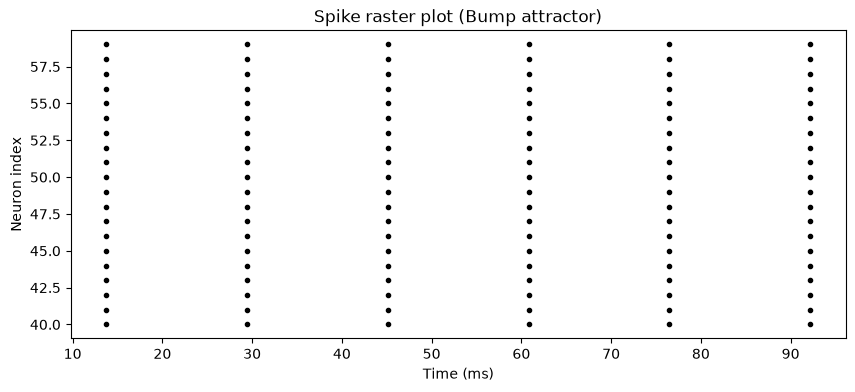

In [2]:

start_scope()
N = 100
tau = 10*ms
v_rest = -65*mV
v_th = -50*mV
v_reset = -65*mV

eqs = '''
dv/dt = (v_rest - v + I_ext + I_syn)/tau : volt (unless refractory)
I_ext : volt
I_syn : volt
'''

neurons = NeuronGroup(N, eqs, threshold='v > v_th', reset='v = v_reset', refractory=2*ms, method='euler')
neurons.v = v_rest
neurons.I_ext = 0*mV

# Synapses
S = Synapses(neurons, neurons, 'w : volt', on_pre='v_post += w')

# Connect with ring topology
S.connect()
# Distance on the ring
S.w = '1*mV * exp(-((i-j)**2)/100) - 0.5*mV'  # Mexican hat connectivity

# Initial stimulus to a specific location
neurons.I_ext[40:60] = 20*mV

M = StateMonitor(neurons, 'v', record=True)
spikemon = SpikeMonitor(neurons)

run(100*ms)

# Remove stimulus
neurons.I_ext = 0*mV

run(200*ms)

plt.figure(figsize=(10, 4))
plt.plot(spikemon.t/ms, spikemon.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Spike raster plot (Bump attractor)')
plt.show()
